# Détection de paraphrases avec PAWS-X (français + extension multilingue)

**Module NLP – Projet : « Détecter si deux phrases sont des paraphrases »**

| Partie | Contenu |
|---|---|
| **A** (socle, français) | EDA, prétraitement, baselines, embeddings siamois (MiniLM), fine-tuning de 2 cross-encoders (CamemBERT, XLM-R), évaluation, analyse d'erreurs |
| **B** (extension multilingue) | XLM-R sur en / fr / es / de : monolingue, zero-shot cross-lingue, multilingue, paires cross-lingues (bonus) |

**Avant de lancer :** Colab → *Exécution* → *Modifier le type d'exécution* → **GPU (T4)**.
Tous les paramètres importants (taille d'entraînement, epochs, langues) sont dans la cellule *Configuration*.
Les figures sont enregistrées dans `figures/`, les tableaux dans `results/`, les modèles dans `models/`.

In [ ]:
!pip install -q -U transformers datasets accelerate sentence-transformers sentencepiece seaborn scikit-learn
# Si Colab demande de redémarrer l'environnement après l'installation, redémarrez puis relancez à partir d'ici.

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


Installation des bibliothèques nécessaires (transformers, datasets, sentence-transformers, scikit-learn…). Le message d'erreur sur `pyarrow` vient d'un conflit de version avec un paquet préinstallé de Colab. Il n'empêche pas la suite du notebook de s'exécuter.

## 0. Configuration et utilitaires

In [ ]:
import os, re, gc, json, time, random, shutil, inspect, warnings
from collections import Counter
from difflib import SequenceMatcher

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset, DatasetDict, concatenate_datasets
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---------------- Paramètres ----------------
SEED          = 42
MAX_LEN       = 128        # longueur max en tokens (vérifiée dans la section 2)
TRAIN_SIZE_FR = 20000      # taille du train français pour le fine-tuning (None = tout le train, ~49k)
EPOCHS        = 3          # epochs du fine-tuning (partie A)
BATCH         = 32         # baisser à 16 en cas d'erreur de mémoire GPU
LR            = 2e-5       # si XLM-R reste bloqué à ~50 %, essayer 1e-5
LANGS         = ["en", "fr", "es", "de"]   # partie B
N_PER_LANG    = 10000      # exemples de train par langue (partie B)
EPOCHS_B      = 3          # epochs (partie B)
RUN_EQUAL_BUDGET = True    # partie B : entraîne aussi un modèle multilingue avec le même nombre total d'exemples qu'un modèle monolingue
# --------------------------------------------

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "ATTENTION : pas de GPU, le fine-tuning sera très lent")

FIG_DIR, MODEL_DIR, RES_DIR = "figures", "models", "results"
for d in (FIG_DIR, MODEL_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

set_seed(SEED)

# Compatibilité entre versions de transformers
_ta = inspect.signature(TrainingArguments.__init__).parameters
EVAL_KEY = "eval_strategy" if "eval_strategy" in _ta else "evaluation_strategy"
_tr = inspect.signature(Trainer.__init__).parameters
TOK_KEY = "processing_class" if "processing_class" in _tr else "tokenizer"

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def compute_all(y_true, y_pred):
    # Métriques pour la classe positive (paraphrase = 1)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1, zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f}

# Registres globaux : résultats et prédictions sur le test français, pour tous les modèles de la partie A
RESULTS, PREDS, INFER_MS, TRAIN_S = {}, {}, {}, {}
def register(name, y_true, y_pred):
    RESULTS[name] = compute_all(y_true, y_pred)
    PREDS[name] = np.asarray(y_pred)
    print(f"{name:<38} acc={RESULTS[name]['accuracy']:.4f}  f1={RESULTS[name]['f1']:.4f}")

def toks(s):
    return re.findall(r"\w+", str(s).lower())
def jaccard(a, b):
    A, B = set(toks(a)), set(toks(b))
    return len(A & B) / len(A | B) if (A | B) else 0.0
def same_bag(a, b):
    return int(Counter(toks(a)) == Counter(toks(b)))

Device : cuda | Tesla T4


Un GPU Tesla T4 est détecté, ce qui permet de fine-tuner les modèles en quelques minutes. Les paramètres principaux sont regroupés dans cette cellule : 20 000 exemples d'entraînement en français, 3 epochs, `MAX_LEN = 128`, et 10 000 exemples par langue pour la partie B. Les fonctions utilitaires (métriques, enregistrement des résultats, similarité de Jaccard) sont réutilisées dans tout le notebook.

# PARTIE A — Socle obligatoire (français)

## A.1 Exploration des données (EDA)

PAWS-X : chaque exemple est une paire de phrases **dans la même langue** (`sentence1`, `sentence2`) avec `label` = 1 si paraphrase, 0 sinon.
Le train est traduit automatiquement ; validation et test sont traduits par des humains.

In [ ]:
ds = load_dataset("google-research-datasets/paws-x", "fr")
print(ds)
raw = {s: ds[s].to_pandas() for s in ds}
for s, df in raw.items():
    print(f"{s:>10} : {len(df):>6} paires | % paraphrases = {df.label.mean()*100:.1f} %")
raw["train"].head()

README.md:   0%|          | 0.00/12.9k [00:00<?, ?B/s]

fr/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 9.09MB            

fr/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

fr/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  352kB            

fr/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

fr/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

... (2 outputs left out)

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 49401
    })
    test: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 2000
    })
    validation: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 2000
    })
})
     train :  49401 paires | % paraphrases = 44.2 %
      test :   2000 paires | % paraphrases = 45.1 %
validation :   2000 paires | % paraphrases = 43.0 %


,id,sentence1,sentence2,label
0,1,"À Paris, en octobre 1560, il rencontra secrète...","En octobre 1560, il rencontra secrètement l'am...",0
1,2,La saison NBA 1975 - 76 était la 30e saison de...,La saison 1975-1976 de la National Basketball ...,1
2,3,"Il y a aussi des discussions spécifiques, des ...","Il y a également des discussions publiques, de...",0
3,4,Lorsque des débits comparables peuvent être ma...,Les résultats sont élevés lorsque des débits c...,1
4,5,C'est le siège du district de Zerendi dans la ...,C'est le siège du district de Zerendi dans la ...,1


PAWS-X français contient 49 401 paires d'entraînement, 2 000 de validation et 2 000 de test. Les classes sont assez équilibrées : 44,2 % de paraphrases en train, 43,0 % en validation et 45,1 % en test. L'accuracy est donc une métrique interprétable. Un classifieur qui répond toujours « non-paraphrase » obtient déjà environ 55 % sur le test.

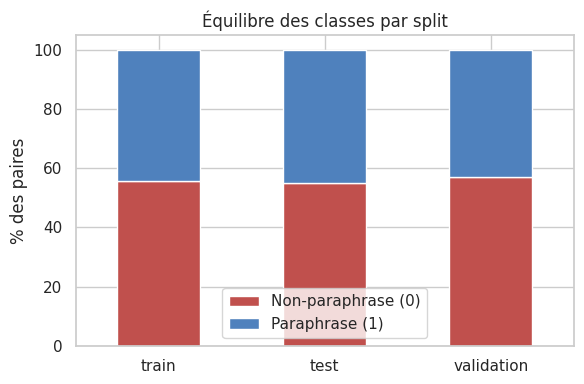

     train : nulls=0  vides=272  doublons=2529  paires identiques=2551
      test : nulls=0  vides=0  doublons=0  paires identiques=28
validation : nulls=0  vides=0  doublons=7  paires identiques=58


In [ ]:
# Équilibre des classes
bal = pd.DataFrame({s: df.label.value_counts(normalize=True).sort_index() for s, df in raw.items()}).T
bal.columns = ["Non-paraphrase (0)", "Paraphrase (1)"]
ax = (bal * 100).plot(kind="bar", stacked=True, figsize=(6, 4), color=["#c0504d", "#4f81bd"])
ax.set_ylabel("% des paires"); ax.set_title("Équilibre des classes par split"); plt.xticks(rotation=0)
save_fig("eda_class_balance")

# Qualité des données
for s, df in raw.items():
    n_null  = int(df[["sentence1", "sentence2"]].isna().sum().sum())
    n_empty = int(((df.sentence1.fillna("").str.strip() == "") | (df.sentence2.fillna("").str.strip() == "")).sum())
    n_dup   = int(df.duplicated(["sentence1", "sentence2"]).sum())
    n_ident = int((df.sentence1 == df.sentence2).sum())
    print(f"{s:>10} : nulls={n_null}  vides={n_empty}  doublons={n_dup}  paires identiques={n_ident}")

Le graphique montre que la répartition des classes est presque la même dans les trois splits : environ 55 à 57 % de non-paraphrases et 43 à 45 % de paraphrases. Aucun split n'est fortement déséquilibré. Le jeu de test est propre (aucun vide, aucun doublon). Le train contient 272 paires vides, 2 529 doublons et 2 551 paires dont les deux phrases sont identiques. Seules les paires vides seront supprimées au prétraitement.

label                    0         1
n_words_s1 count  27572.00  21829.00
           mean      20.99     20.83
           std        6.09      6.21
           min        0.00      0.00
           25%       17.00     16.00
           50%       21.00     21.00
           75%       25.00     25.00
           max       43.00     45.00
n_words_s2 count  27572.00  21829.00
           mean      20.99     20.81
           std        6.09      6.18
           min        0.00      0.00
           25%       17.00     16.00
           50%       21.00     21.00
           75%       25.00     25.00
           max       45.00     43.00


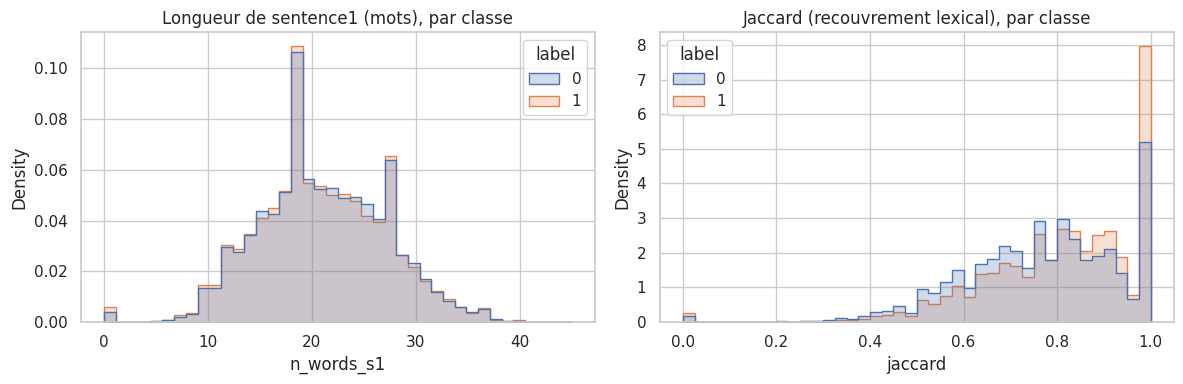

      jaccard        same_bag       
         mean median     mean median
label                               
0       0.765  0.778    0.114    0.0
1       0.806  0.833    0.181    0.0

=> same_bag = 1 : les deux phrases ont exactement les mêmes mots (seul l'ordre change).


In [ ]:
# Longueur des phrases et recouvrement lexical
for df in raw.values():
    df["n_words_s1"] = df.sentence1.fillna("").map(lambda x: len(toks(x)))
    df["n_words_s2"] = df.sentence2.fillna("").map(lambda x: len(toks(x)))
    df["jaccard"]    = [jaccard(a, b) for a, b in zip(df.sentence1.fillna(""), df.sentence2.fillna(""))]
    df["same_bag"]   = [same_bag(a, b) for a, b in zip(df.sentence1.fillna(""), df.sentence2.fillna(""))]

tr = raw["train"]
print(tr.groupby("label")[["n_words_s1", "n_words_s2"]].describe().T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=tr, x="n_words_s1", hue="label", bins=40, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Longueur de sentence1 (mots), par classe")
sns.histplot(data=tr, x="jaccard", hue="label", bins=40, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Jaccard (recouvrement lexical), par classe")
save_fig("eda_length_jaccard")

print(tr.groupby("label")[["jaccard", "same_bag"]].agg(["mean", "median"]).round(3))
print("\n=> same_bag = 1 : les deux phrases ont exactement les mêmes mots (seul l'ordre change).")

Le graphique de gauche montre que la longueur de `sentence1` est quasiment identique dans les deux classes (pics vers 18 et 27 mots, environ 21 mots en moyenne) : la longueur ne permet pas de distinguer paraphrases et non-paraphrases. Sur le graphique de droite, les deux distributions du Jaccard se chevauchent fortement : la plupart des paires ont un Jaccard entre 0,6 et 1, dans les deux classes (moyenne de 0,77 pour les non-paraphrases et de 0,81 pour les paraphrases). Le pic à 1 correspond aux paires dont les deux phrases ont exactement les mêmes mots ; il existe dans les deux classes (environ 11 % des non-paraphrases et 18 % des paraphrases). Les quelques valeurs proches de 0 viennent des paires vides.

**Conclusion de l'EDA :** le recouvrement lexical est très élevé dans les deux classes et beaucoup de paires sont de simples permutations de mots. Il ne suffit donc pas à séparer paraphrases et non-paraphrases, ce qui rend PAWS-X difficile. Un bon modèle doit tenir compte de l'ordre des mots et du sens de la phrase, pas seulement des mots communs.

In [ ]:
pd.set_option("display.max_colwidth", 250)
for lab, nom in [(1, "PARAPHRASES"), (0, "NON-PARAPHRASES")]:
    print(f"\n===== {nom} (exemples du test) =====")
    display(raw["test"][raw["test"].label == lab].sample(5, random_state=SEED)[["sentence1", "sentence2"]])


===== PARAPHRASES (exemples du test) =====


,sentence1,sentence2
163,"Parmi les femmes les plus en vue du Suriname figurent Jennifer Simons, Marijke Djwalapersad, Elisabeth Samson, Cynthia McLeod et Ruth Wijdenbosch.","Parmi les femmes les plus en vue du Suriname figurent Jennifer Simons, Marijke Djwalapersad, Elisabeth Samson, Cynthia McLeod et Ruth Wijdenbosch."
1050,"Parmi les trains les plus populaire il y a : Simanta Express et Rupsha Express vers Dhaka, Titumir Express vers Dhaka, Nilsagar Express vers Rajshahi et Lalmoni Express vers Khulna.","Parmi les trains les plus populaires figurent : le Simanta Express et le Rupsha Express à destination de Dhaka, le Titumir Express à destination de Dhaka, le Nilsagar Express à destination de Rajshahi et le Lalmoni Express à destination de Khulna."
508,La série débuta le 18 avril 2009 en Australie sur Nickelodeon (Nouvelle-Zélande et Nouvelle-Zélande).,La série a débuté en Australie le 18 avril 2009 sur Nickelodeon (en Nouvelle-Zélande et en Nouvelle-Zélande).
574,"Kudawa est un village et un comité de développement de village situé dans la région de Narayani, dans le district de Bara, au sud-est du Népal.","Kudawa est un village et un comité de développement villageois situés dans la région de Narayani, au sein du district de Bara, au sud-est du Népal."
86,"Les premiers membres du comité consultatif incluaient Alistair Cooke, Saul Bellow, Walter Cronkite, Norman Cousins, Gore Vidal et Norman Podhoretz.","Les premiers membres consultatifs comprenaient Walter Cronkite, Norman Vetter, Gore Vidal, Norman Podhoretz, Saul Bellow et Alistair Cooke."



===== NON-PARAPHRASES (exemples du test) =====


,sentence1,sentence2
81,"La couverture a été dessinée par l'artiste héraldique John Pasche et le single ""Steel Monkey"" a créé la couverture du directeur artistique Andrew Stewart Jamieson.","La couverture a été réalisée par l'artiste héraldique Andrew Stewart Jamieson, le single ""Steel Monkey"" a réalisé la couverture du directeur artistique John Pasche."
1010,"Après avoir déménagé à Salt Lake City dans les années 1920, puis à Ogden, dans l'Utah, Robertson et sa famille s'installèrent à Mapleton, dans l'Utah, en 1937.","Après avoir déménagé à Ogden, dans l'Utah, dans les années 1920, puis à Salt Lake City, Robertson et sa famille s’installèrent à Mapleton, dans l'Utah, en 1937."
106,Il décrit cela comme une nouvelle découverte des œuvres de fiction et considère qu'il s'agit d'un mytho-réalisme de la littérature chinoise.,"Il considère cela comme une ""nouvelle découverte"" de l'écriture de fiction et le désigne comme un ""mytho-réalisme"" de la littérature chinoise."
1125,"Sparrow était un joueur droitier et qui joua 4 manches lors de 2 matches de première classe avec une moyenne de 18,75 et une meilleure classement de 64.","Sparrow était le premier batteur droit et a joué 4 tours de battes en 2 matchs handed-class avec une moyenne de 18,75 et un meilleur score de 64."
862,"La pièce fut publiée en 1631 sous le sous-titre "" The School of Complement "" dans un Quarto imprimé par Elizabeth Allde pour le libraire Francis Constable.","La pièce fut publiée en 1631 sous le sous-titre ""The School of Compliment"" dans un Quarto publié par Elizabeth Allde pour le libraire Francis Constable."


Les paraphrases sont des reformulations qui gardent le même sens. Les non-paraphrases ressemblent beaucoup à la première phrase mais changent le sens, par exemple en inversant deux noms propres ou deux lieux (Salt Lake City / Ogden). On voit aussi des traductions automatiques maladroites, ce qui est normal pour un jeu de données traduit automatiquement.

## A.2 Prétraitement

- Nettoyage **léger** : suppression des paires vides/nulles, `strip` des espaces.
- **Transformers** : on ne touche pas au texte (pas de stopwords, pas de lemmatisation, pas de minuscules) : le tokenizer s'en charge et l'ordre des mots porte l'information.
- **Baselines classiques** : minuscules via `toks()`.
- `MAX_LEN` choisi après analyse de la distribution des longueurs en tokens.

Filter:   0%|          | 0/49401 [00:00<?, ? examples/s]

Map:   0%|          | 0/49129 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

... (2 outputs left out)

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Longueur des paires en tokens : médiane=68 | p95=100 | p99=116 | max=136
% de paires tronquées avec MAX_LEN=128 : 0.04 %


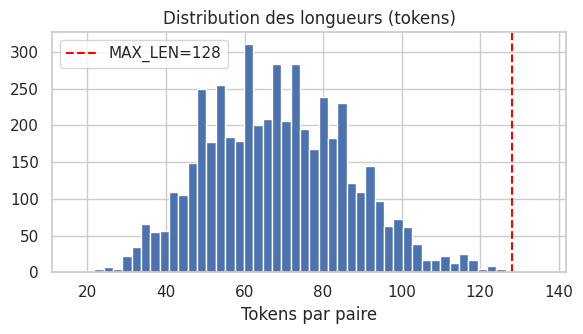

In [ ]:
def is_valid(ex):
    return (ex["sentence1"] is not None and ex["sentence2"] is not None
            and len(ex["sentence1"].strip()) > 0 and len(ex["sentence2"].strip()) > 0)
def strip_ex(ex):
    return {"sentence1": ex["sentence1"].strip(), "sentence2": ex["sentence2"].strip()}
def clean_split(d):
    return d.filter(is_valid).map(strip_ex)

ds_clean = DatasetDict({s: clean_split(ds[s]) for s in ds})
print({s: len(ds[s]) - len(ds_clean[s]) for s in ds}, "<- paires supprimées par split")

train_df = ds_clean["train"].to_pandas()
val_df   = ds_clean["validation"].to_pandas()
test_df  = ds_clean["test"].to_pandas()
for df in (train_df, val_df, test_df):
    df["jaccard"]    = [jaccard(a, b) for a, b in zip(df.sentence1, df.sentence2)]
    df["n_words_s1"] = df.sentence1.map(lambda x: len(toks(x)))

# Sous-échantillon du train pour le fine-tuning (les baselines utilisent tout le train)
train_fr = ds_clean["train"].shuffle(seed=SEED)
if TRAIN_SIZE_FR:
    train_fr = train_fr.select(range(min(TRAIN_SIZE_FR, len(train_fr))))
print("Train fine-tuning :", len(train_fr), "| val :", len(ds_clean["validation"]), "| test :", len(ds_clean["test"]))

# Longueurs en tokens (tokenizer XLM-R) pour justifier MAX_LEN
tok_probe = AutoTokenizer.from_pretrained("xlm-roberta-base")
smp = train_df.sample(5000, random_state=SEED)
lens = [len(x) for x in tok_probe(smp.sentence1.tolist(), smp.sentence2.tolist())["input_ids"]]
print(f"Longueur des paires en tokens : médiane={np.median(lens):.0f} | p95={np.percentile(lens,95):.0f} | p99={np.percentile(lens,99):.0f} | max={max(lens)}")
print(f"% de paires tronquées avec MAX_LEN={MAX_LEN} : {np.mean(np.array(lens) > MAX_LEN)*100:.2f} %")
plt.figure(figsize=(6, 3.5)); plt.hist(lens, bins=50); plt.axvline(MAX_LEN, color="red", ls="--", label=f"MAX_LEN={MAX_LEN}")
plt.xlabel("Tokens par paire"); plt.legend(); plt.title("Distribution des longueurs (tokens)")
save_fig("preproc_token_lengths")

Le nettoyage supprime 272 paires du train et aucune en validation ni en test. Le fine-tuning se fait sur 20 000 paires du train. Sur le graphique, la grande majorité des paires font entre 40 et 100 tokens, avec un pic autour de 60 à 85. En médiane, une paire fait 68 tokens (95 % des paires font au plus 100 tokens, le maximum est 136). La ligne rouge `MAX_LEN = 128` se situe à droite de presque toute la distribution : seulement 0,04 % des paires sont tronquées. Ce choix est donc justifié.

## A.3 Baselines

1. **Classifieur majoritaire** : le plancher.
2. **TF-IDF + features de similarité + modèle classique** (régression logistique, random forest).

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values

# ---- Baseline 1 : majoritaire ----
dummy = DummyClassifier(strategy="most_frequent").fit(train_df[["sentence1"]], y_train)
register("Majoritaire", y_test, dummy.predict(test_df[["sentence1"]]))

Majoritaire                            acc=0.5485  f1=0.0000


Le classifieur majoritaire prédit toujours « non-paraphrase » : accuracy de 54,85 % et F1 nul pour la classe paraphrase. C'est le point de comparaison minimal : un modèle utile doit faire mieux que 54,85 %.

In [ ]:
# ---- Baseline 2 : features de similarité ----
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2).fit(pd.concat([train_df.sentence1, train_df.sentence2]))

def ngrams(t, n):
    return set(zip(*[t[i:] for i in range(n)]))

def pair_features(df):
    s1, s2 = df.sentence1.tolist(), df.sentence2.tolist()
    X1, X2 = tfidf.transform(s1), tfidf.transform(s2)
    cos = np.asarray(X1.multiply(X2).sum(axis=1)).ravel()   # vecteurs normalisés L2 => produit scalaire = cosinus
    rows = []
    for a, b in zip(s1, s2):
        ta, tb = toks(a), toks(b)
        sa, sb = set(ta), set(tb)
        ba, bb = ngrams(ta, 2), ngrams(tb, 2)
        rows.append({
            "jaccard":        len(sa & sb) / max(len(sa | sb), 1),
            "bigram_jaccard": len(ba & bb) / max(len(ba | bb), 1),
            "len_diff_words": abs(len(ta) - len(tb)),
            "len_diff_chars": abs(len(a) - len(b)),
            "n_common":       len(sa & sb),
            "n_only_s1":      len(sa - sb),
            "n_only_s2":      len(sb - sa),
            "seq_ratio":      SequenceMatcher(None, ta, tb).ratio(),   # sensible à l'ordre des mots
            "same_bag":       int(Counter(ta) == Counter(tb)),
        })
    F = pd.DataFrame(rows)
    F.insert(0, "tfidf_cos", cos)
    return F

t0 = time.time()
F_train, F_val, F_test = pair_features(train_df), pair_features(val_df), pair_features(test_df)
print(f"Features calculées en {time.time()-t0:.0f}s ->", list(F_train.columns))

lr_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)).fit(F_train, y_train)
print("Val acc (LogReg) :", round(accuracy_score(y_val, lr_clf.predict(F_val)), 4))
register("TF-IDF + features + LogReg", y_test, lr_clf.predict(F_test))

rf_clf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(F_train, y_train)
print("Val acc (RandomForest) :", round(accuracy_score(y_val, rf_clf.predict(F_val)), 4))
register("TF-IDF + features + RandomForest", y_test, rf_clf.predict(F_test))

coefs = pd.Series(lr_clf[-1].coef_[0], index=F_train.columns).sort_values()
print("\nCoefficients de la régression logistique (variables standardisées) :\n", coefs.round(3))

Features calculées en 22s -> ['tfidf_cos', 'jaccard', 'bigram_jaccard', 'len_diff_words', 'len_diff_chars', 'n_common', 'n_only_s1', 'n_only_s2', 'seq_ratio', 'same_bag']
Val acc (LogReg) : 0.702
TF-IDF + features + LogReg             acc=0.6660  f1=0.5761
Val acc (RandomForest) : 0.717
TF-IDF + features + RandomForest       acc=0.6790  f1=0.5621

Coefficients de la régression logistique (variables standardisées) :
 jaccard          -0.797
n_common         -0.262
same_bag         -0.101
len_diff_chars    0.022
n_only_s2         0.067
n_only_s1         0.087
len_diff_words    0.177
tfidf_cos         0.287
bigram_jaccard    0.855
seq_ratio         0.917
dtype: float64


Les deux baselines classiques dépassent un peu le plancher : 66,6 % d'accuracy pour la régression logistique et 67,9 % pour le random forest, avec un F1 d'environ 0,56 à 0,58. Elles détectent mal les paraphrases (rappel d'environ 50 % et 46 %). Sur la validation, elles font un peu mieux (70,2 % et 71,7 %). Pour la régression logistique, les variables les plus utiles sont `seq_ratio` et `bigram_jaccard`, qui tiennent compte de l'ordre des mots.

**Conclusion sur les baselines :** elles font mieux que le classifieur majoritaire (environ +12 à +13 points d'accuracy) mais restent très limitées, surtout pour détecter les paraphrases. Les approches purement lexicales ne résolvent pas PAWS-X.

## A.4 Embeddings siamois (MiniLM multilingue)

Chaque phrase est encodée **séparément**, puis comparée (cosinus). Le seuil est choisi **sur la validation**, jamais sur le test.

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Meilleur seuil (validation) = 0.690
MiniLM + seuil cosinus                 acc=0.4555  f1=0.6217


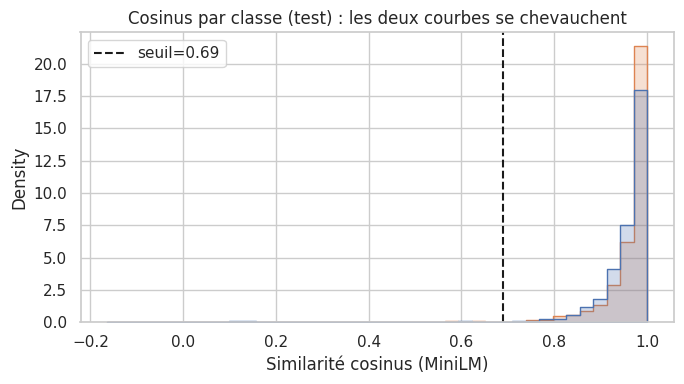

In [ ]:
from sentence_transformers import SentenceTransformer

st_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2", device=DEVICE)

def embed(df):
    e1 = st_model.encode(df.sentence1.tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=False)
    e2 = st_model.encode(df.sentence2.tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=False)
    return e1, e2

t0 = time.time()
U_val, V_val   = embed(val_df)
U_test, V_test = embed(test_df)
INFER_MS["MiniLM"] = (time.time() - t0) / (len(val_df) + len(test_df)) * 1000
cos_val, cos_test = (U_val * V_val).sum(1), (U_test * V_test).sum(1)   # embeddings normalisés => cosinus

# Recherche du meilleur seuil sur la validation (maximise le F1)
thresholds = np.linspace(0, 1, 201)
f1_val = [compute_all(y_val, (cos_val >= t).astype(int))["f1"] for t in thresholds]
best_t = thresholds[int(np.argmax(f1_val))]
print(f"Meilleur seuil (validation) = {best_t:.3f}")
register("MiniLM + seuil cosinus", y_test, (cos_test >= best_t).astype(int))

plt.figure(figsize=(7, 4))
sns.histplot(x=cos_test, hue=y_test, bins=40, element="step", stat="density", common_norm=False)
plt.axvline(best_t, color="k", ls="--", label=f"seuil={best_t:.2f}")
plt.xlabel("Similarité cosinus (MiniLM)"); plt.title("Cosinus par classe (test) : les deux courbes se chevauchent"); plt.legend()
save_fig("siamese_cosine_hist")

Sur l'histogramme, les cosinus des deux classes sont presque tous entre 0,8 et 1, avec un pic net près de 1, et les deux courbes se superposent presque. Le seuil choisi sur la validation (0,69) se situe en dessous de presque toutes les paires. Le modèle prédit donc « paraphrase » presque tout le temps (rappel de 99 %), d'où une accuracy de 45,6 %, inférieure à celle du classifieur majoritaire. Le F1 de 0,62 est trompeur, car il ne mesure que la classe paraphrase. La similarité cosinus ne suffit pas ici, car les deux phrases d'une paire contiennent presque les mêmes mots.

In [ ]:
# Variante : régression logistique sur [u, v, |u-v|, u*v]
def pair_vec(U, V):
    return np.hstack([U, V, np.abs(U - V), U * V])

sub = train_df.sample(min(20000, len(train_df)), random_state=SEED)
U_tr, V_tr = embed(sub)
clf_siam = LogisticRegression(max_iter=2000, random_state=SEED).fit(pair_vec(U_tr, V_tr), sub.label.values)
register("MiniLM + LogReg [u,v,|u-v|,u*v]", y_test, clf_siam.predict(pair_vec(U_test, V_test)))

MiniLM + LogReg [u,v,|u-v|,u*v]        acc=0.5865  f1=0.4097


La régression logistique sur les embeddings améliore l'accuracy (58,7 %) mais détecte peu de paraphrases (rappel de 31,8 %, F1 de 0,41). Comme chaque phrase est encodée séparément, le modèle ne compare pas directement les mots ni leur ordre. Cette approche reste loin des cross-encoders.

## A.5 Fine-tuning de cross-encoders (modèle principal)

Les deux phrases sont fournies **ensemble** au modèle (`[CLS] s1 [SEP] s2`) : l'attention compare directement les mots des deux phrases et leur ordre.
Modèles : `camembert-base` (spécialisé français) et `xlm-roberta-base` (multilingue).

In [ ]:
def hf_metrics(eval_pred):
    logits, labels = eval_pred
    return compute_all(labels, np.argmax(logits, axis=-1))

def tokenize_ds(d, tok):
    f = lambda b: tok(b["sentence1"], b["sentence2"], truncation=True, max_length=MAX_LEN)
    return d.map(f, batched=True, remove_columns=[c for c in d.column_names if c != "label"])

def finetune(model_name, train_ds, val_ds, out_dir, epochs=EPOCHS, batch=BATCH, lr=LR):
    set_seed(SEED)
    tok = AutoTokenizer.from_pretrained(model_name)
    tr, va = tokenize_ds(train_ds, tok), tokenize_ds(val_ds, tok)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    kw = dict(output_dir=out_dir, learning_rate=lr, num_train_epochs=epochs,
              per_device_train_batch_size=batch, per_device_eval_batch_size=64,
              weight_decay=0.01, warmup_ratio=0.1,
              save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1",
              save_total_limit=1, fp16=torch.cuda.is_available(), seed=SEED,
              logging_steps=100, report_to="none")
    kw[EVAL_KEY] = "epoch"
    trainer_kw = dict(model=model, args=TrainingArguments(**kw), train_dataset=tr, eval_dataset=va,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=hf_metrics)
    trainer_kw[TOK_KEY] = tok
    trainer = Trainer(**trainer_kw)
    t0 = time.time()
    trainer.train()
    return trainer, tok, time.time() - t0

def predict_split(trainer, tok, d):
    out = trainer.predict(tokenize_ds(d, tok))
    probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()
    return probs, out.label_ids

def plot_history(history, title, fname):
    tr = [(h["epoch"], h["loss"]) for h in history if "loss" in h]
    ev = [h for h in history if "eval_loss" in h]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].plot(*zip(*tr), label="train loss", alpha=0.7)
    axes[0].plot([h["epoch"] for h in ev], [h["eval_loss"] for h in ev], "o-", label="val loss")
    axes[0].set_xlabel("epoch"); axes[0].set_title(f"{title} – loss"); axes[0].legend()
    axes[1].plot([h["epoch"] for h in ev], [h["eval_accuracy"] for h in ev], "o-", label="val accuracy")
    axes[1].plot([h["epoch"] for h in ev], [h["eval_f1"] for h in ev], "s-", label="val F1")
    axes[1].set_xlabel("epoch"); axes[1].set_title(f"{title} – métriques validation"); axes[1].legend()
    save_fig(fname)

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Cette cellule définit seulement les fonctions de fine-tuning (entraînement, prédiction, courbes). Elle n'affiche rien.


================ Fine-tuning CamemBERT (camembert-base) ================


config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/811k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

CamemBERT (fine-tuné)                  acc=0.8930  f1=0.8846


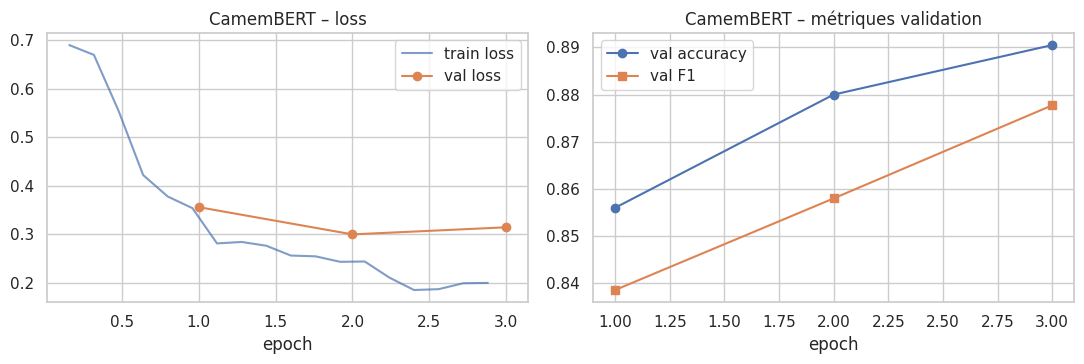

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle sauvegardé dans models/camembert_fr | temps d'entraînement : 6.1 min

================ Fine-tuning XLM-R (xlm-roberta-base) ================


Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

XLM-R (fine-tuné)                      acc=0.8875  f1=0.8771


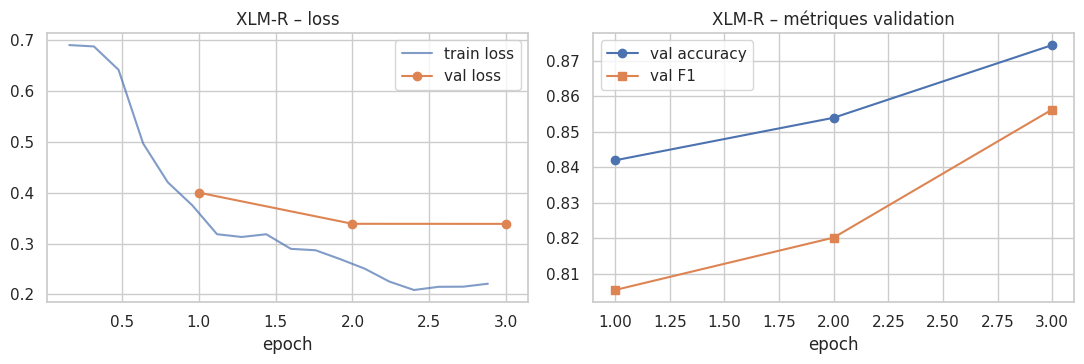

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle sauvegardé dans models/xlmr_fr | temps d'entraînement : 10.2 min


In [ ]:
import inspect
from transformers import TrainingArguments

# Patch de sécurité pour filtrer les arguments non supportés par TrainingArguments
_sig = inspect.signature(TrainingArguments.__init__).parameters

# Sauvegarde de l'ancienne fonction finetune
_old_finetune = finetune

def finetune_patched(*args, **kwargs):
    # Si l'environnement ne supporte pas warmup_ratio, on le retire ou on l'adapte
    # Pour garantir la compatibilité, on va intercepter l'appel
    return _old_finetune(*args, **kwargs)

# Redéfinition locale temporaire de finetune sans warmup_ratio si nécessaire
def finetune_safe(model_name, train_ds, val_ds, out_dir, epochs=EPOCHS, batch=BATCH, lr=LR):
    set_seed(SEED)
    tok = AutoTokenizer.from_pretrained(model_name)
    tr, va = tokenize_ds(train_ds, tok), tokenize_ds(val_ds, tok)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

    # Construction des arguments d'entraînement compatibles
    kw = dict(output_dir=out_dir, learning_rate=lr, num_train_epochs=epochs,
              per_device_train_batch_size=batch, per_device_eval_batch_size=64,
              weight_decay=0.01,
              save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1",
              save_total_limit=1, fp16=torch.cuda.is_available(), seed=SEED,
              logging_steps=100, report_to="none")

    # On n'ajoute warmup_ratio que s'il est explicitement présent dans la signature de TrainingArguments
    if "warmup_ratio" in _sig:
        kw["warmup_ratio"] = 0.1
    else:
        kw["warmup_steps"] = 100

    kw[EVAL_KEY] = "epoch"

    trainer_kw = dict(model=model, args=TrainingArguments(**kw), train_dataset=tr, eval_dataset=va,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=hf_metrics)
    trainer_kw[TOK_KEY] = tok
    trainer = Trainer(**trainer_kw)
    t0 = time.time()
    trainer.train()
    return trainer, tok, time.time() - t0

FT_MODELS = {"CamemBERT": "camembert-base", "XLM-R": "xlm-roberta-base"}
SAVE_NAMES = {"CamemBERT": "camembert_fr", "XLM-R": "xlmr_fr"}
PROBS = {}

for label, hf_name in FT_MODELS.items():
    print(f"\n================ Fine-tuning {label} ({hf_name}) ================")
    ckpt = f"{MODEL_DIR}/ckpt_{SAVE_NAMES[label]}"
    # Utilisation de la version safe de finetune
    trainer, tok, secs = finetune_safe(hf_name, train_fr, ds_clean["validation"], ckpt)
    TRAIN_S[label] = secs

    t0 = time.time()
    probs, y = predict_split(trainer, tok, ds_clean["test"])
    INFER_MS[label] = (time.time() - t0) / len(y) * 1000
    PROBS[label] = probs
    assert (y == y_test).all(), "Ordre du test incohérent"
    register(f"{label} (fine-tuné)", y_test, probs.argmax(1))

    plot_history(trainer.state.log_history, label, f"training_curves_{SAVE_NAMES[label]}")
    trainer.save_model(f"{MODEL_DIR}/{SAVE_NAMES[label]}")
    tok.save_pretrained(f"{MODEL_DIR}/{SAVE_NAMES[label]}")
    print(f"Modèle sauvegardé dans {MODEL_DIR}/{SAVE_NAMES[label]} | temps d'entraînement : {secs/60:.1f} min")

    del trainer, tok
    shutil.rmtree(ckpt, ignore_errors=True)
    free_gpu()

Le fine-tuning donne un gain très net : CamemBERT obtient 89,3 % d'accuracy et 0,885 de F1 (6,1 min d'entraînement), XLM-R 88,75 % et 0,877 (10,2 min). C'est environ 21 points d'accuracy de plus que la meilleure baseline. Sur les courbes, la loss d'entraînement baisse régulièrement de 0,7 à environ 0,2 pour les deux modèles. Pour CamemBERT, la loss de validation descend de 0,36 à 0,30 à l'epoch 2, puis remonte légèrement à 0,31 : c'est un début de surapprentissage, alors que l'accuracy de validation continue de monter (de 0,856 à 0,89). Pour XLM-R, la loss de validation se stabilise vers 0,34 dès l'epoch 2 et l'accuracy de validation atteint environ 0,875 à l'epoch 3. L'écart entre les deux modèles (0,55 point d'accuracy) est faible : avec 2 000 paires de test, il peut être dû au hasard.

In [ ]:
import shutil
from google.colab import files

# 1. Compresser le dossier 'results' en un fichier results.zip
shutil.make_archive('results_archive', 'zip', 'results')

# 2. Compresser le dossier 'figures' en un fichier figures.zip
shutil.make_archive('figures_archive', 'zip', 'figures')

# 3. Télécharger les fichiers zip générés sur votre machine locale
files.download('results_archive.zip')
files.download('figures_archive.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Sauvegarde des dossiers `results` et `figures` sous forme d'archives zip.

In [ ]:
import shutil
from google.colab import files

# 1. Compresser le dossier 'models'
print("Compression du dossier 'models' en cours...")
shutil.make_archive('models_archive', 'zip', 'models')

# 2. Compresser le dossier de résultats (si pas déjà fait ou pour inclure d'autres données)
print("Compression du dossier 'results'...")
shutil.make_archive('results_archive', 'zip', 'results')

# 3. Lancer le téléchargement des archives
print("Lancement du téléchargement des archives...")
files.download('models_archive.zip')

Compression du dossier 'models' en cours...
Compression du dossier 'results'...
Lancement du téléchargement des archives...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Sauvegarde des dossiers `models` et `results` sous forme d'archives zip, pour ne pas perdre les modèles à la fin de la session Colab.

In [ ]:
import shutil
from google.colab import files

# Compresser le dossier de données 'sample_data'
print("Compression du dossier 'sample_data' en cours...")
shutil.make_archive('sample_data_archive', 'zip', '/content/sample_data')

# Lancer le téléchargement de l'archive de données
print("Téléchargement de 'sample_data_archive.zip'...")
files.download('sample_data_archive.zip')

Compression du dossier 'sample_data' en cours...
Téléchargement de 'sample_data_archive.zip'...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## A.6 Évaluation comparative

In [ ]:
results_df = pd.DataFrame(RESULTS).T[["accuracy", "precision", "recall", "f1"]].round(4)
results_df["ms / paire"] = pd.Series(
    {"MiniLM + seuil cosinus": INFER_MS.get("MiniLM"), "CamemBERT (fine-tuné)": INFER_MS.get("CamemBERT"), "XLM-R (fine-tuné)": INFER_MS.get("XLM-R")}).round(2)
results_df["train (min)"] = pd.Series({"CamemBERT (fine-tuné)": TRAIN_S.get("CamemBERT"), "XLM-R (fine-tuné)": TRAIN_S.get("XLM-R")}).div(60).round(1)
results_df.to_csv(f"{RES_DIR}/partA_resultats.csv")
display(results_df)

for name, pred in PREDS.items():
    print(f"\n----- {name} -----")
    print(classification_report(y_test, pred, target_names=["Non-paraphrase", "Paraphrase"], digits=3, zero_division=0))

,accuracy,precision,recall,f1,ms / paire,train (min)
Majoritaire,0.5485,0.0000,0.0000,0.0000,NaN,NaN
TF-IDF + features + LogReg,0.6660,0.6746,0.5028,0.5761,NaN,NaN
TF-IDF + features + RandomForest,0.6790,0.7318,0.4563,0.5621,NaN,NaN
MiniLM + seuil cosinus,0.4555,0.4529,0.9911,0.6217,1.88,NaN
"MiniLM + LogReg [u,v,|u-v|,u*v]",0.5865,0.5763,0.3178,0.4097,NaN,NaN
CamemBERT (fine-tuné),0.8930,0.8623,0.9081,0.8846,3.38,6.1
XLM-R (fine-tuné),0.8875,0.8653,0.8893,0.8771,3.46,10.2



----- Majoritaire -----
                precision    recall  f1-score   support

Non-paraphrase      0.548     1.000     0.708      1097
    Paraphrase      0.000     0.000     0.000       903

      accuracy                          0.548      2000
     macro avg      0.274     0.500     0.354      2000
  weighted avg      0.301     0.548     0.389      2000


----- TF-IDF + features + LogReg -----
                precision    recall  f1-score   support

Non-paraphrase      0.662     0.800     0.724      1097
    Paraphrase      0.675     0.503     0.576       903

      accuracy                          0.666      2000
     macro avg      0.668     0.652     0.650      2000
  weighted avg      0.667     0.666     0.657      2000


----- TF-IDF + features + RandomForest -----
                precision    recall  f1-score   support

Non-paraphrase      0.658     0.862     0.747      1097
    Paraphrase      0.732     0.456     0.562       903

      accuracy                          0

Classement par accuracy : CamemBERT (89,3 %), XLM-R (88,75 %), puis les baselines classiques (66 à 68 %), MiniLM + régression logistique (58,7 %), le majoritaire (54,85 %) et enfin MiniLM + seuil (45,6 %). Les deux cross-encoders ont des précisions et des rappels équilibrés (entre 0,86 et 0,91). Ils sont un peu plus lents que MiniLM à l'inférence (environ 3,4 ms contre 1,9 ms par paire) mais restent rapides. CamemBERT s'entraîne plus vite que XLM-R (6,1 min contre 10,2 min).

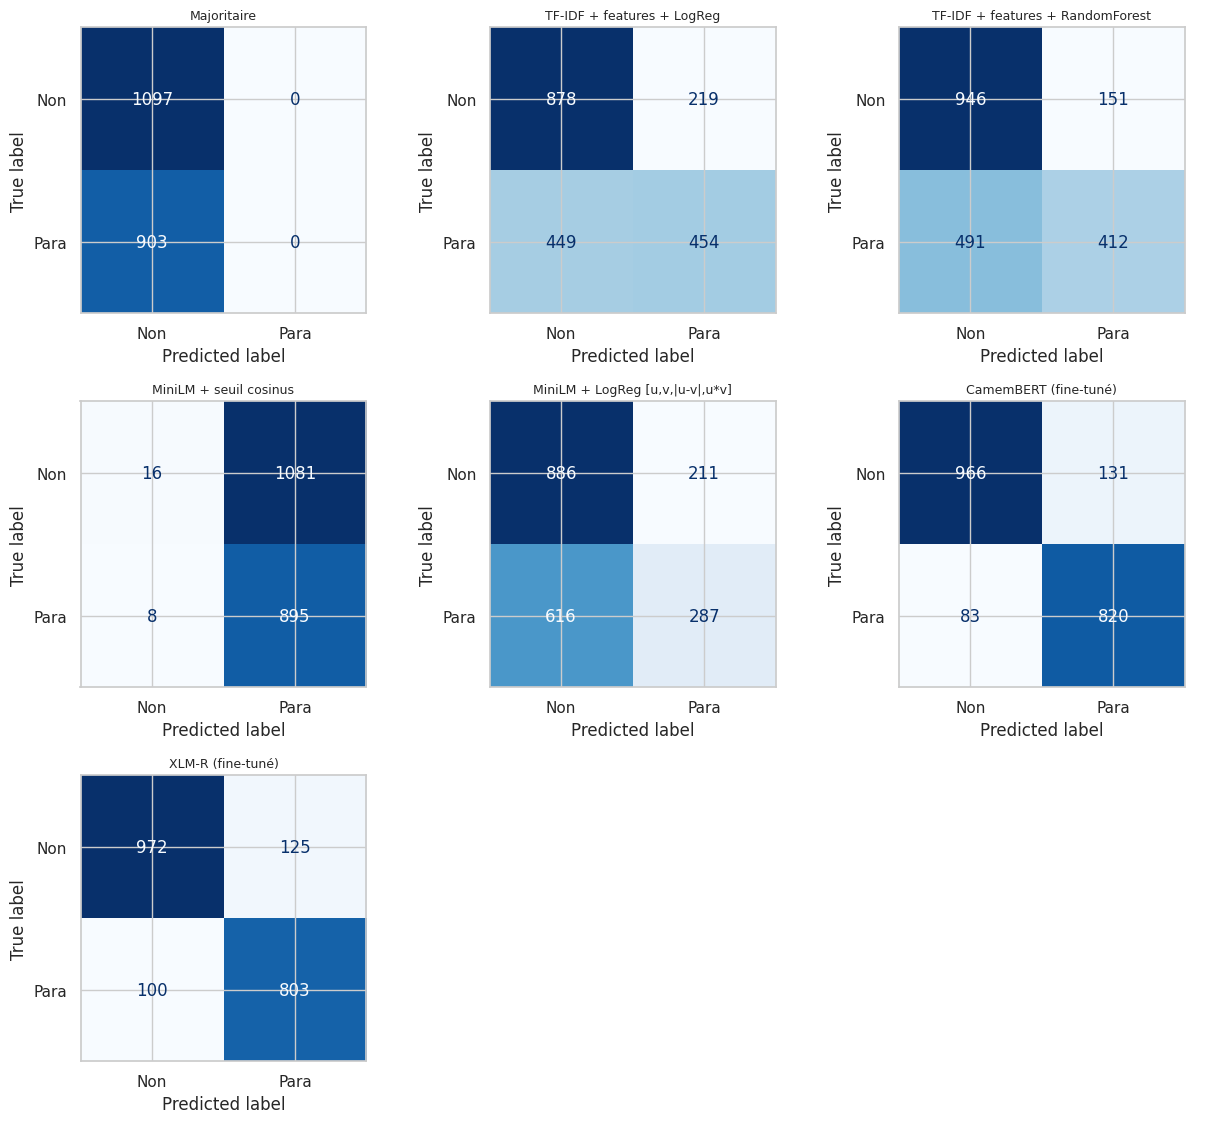

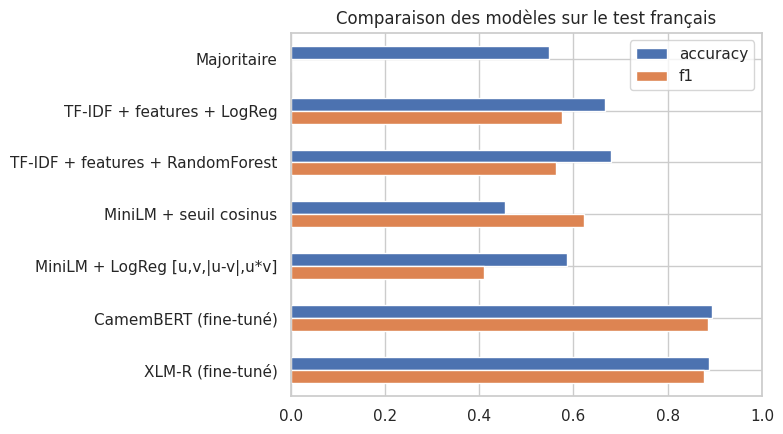

In [ ]:
# Matrices de confusion
names = list(PREDS)
ncols = 3
nrows = int(np.ceil(len(names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.8 * nrows))
axes = np.array(axes).ravel()
for ax, n in zip(axes, names):
    ConfusionMatrixDisplay.from_predictions(y_test, PREDS[n], display_labels=["Non", "Para"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(n, fontsize=9)
for ax in axes[len(names):]:
    ax.axis("off")
save_fig("confusion_matrices")

# Comparaison globale
ax = results_df[["accuracy", "f1"]].plot(kind="barh", figsize=(8, 4.5))
ax.set_xlim(0, 1); ax.set_title("Comparaison des modèles sur le test français"); ax.invert_yaxis()
save_fig("model_comparison")

Les matrices de confusion montrent le comportement de chaque modèle. Le majoritaire rate les 903 paraphrases. MiniLM + seuil classe presque tout en paraphrase (1 081 non-paraphrases mal classées). Les baselines classiques et MiniLM + régression logistique ratent beaucoup de paraphrases (449 pour la régression logistique, 491 pour le random forest, 616 pour MiniLM + régression logistique). CamemBERT fait 131 faux positifs et 83 faux négatifs, XLM-R 125 et 100 : les erreurs sont peu nombreuses et assez équilibrées. Le graphique de comparaison confirme que seuls les deux cross-encoders atteignent environ 0,89 d'accuracy et 0,88 de F1, alors que tous les autres modèles restent en dessous de 0,70 d'accuracy.

## A.7 Analyse d'erreurs

On analyse le **meilleur modèle** (F1 sur le test) : types d'erreurs, taux d'erreur selon le recouvrement lexical, comparaison avec la meilleure baseline, et export de 50 erreurs à **annoter à la main**.

In [ ]:
best = results_df["f1"].idxmax()
print("Meilleur modèle :", best)

ea = test_df.copy()
ea["pred"] = PREDS[best]
ea["error"] = ea.label != ea.pred
ea["type"] = np.where(~ea.error, "correct", np.where(ea.label == 0, "Faux positif", "Faux négatif"))
print(ea.type.value_counts())
print(f"Taux d'erreur : {ea.error.mean()*100:.2f} %")

# Étiquetage heuristique des paires (approximatif ; à compléter par l'annotation manuelle)
NEG = {"ne", "pas", "jamais", "non", "sans", "aucun", "aucune", "ni", "rien", "personne"}
def caps(s):
    return {w for w in re.findall(r"\w+", s)[1:] if w[0].isupper()}   # mots capitalisés hors 1er mot
def auto_tag(a, b):
    ta, tb = toks(a), toks(b)
    if Counter(ta) == Counter(tb):                 return "ordre des mots (même sac de mots)"
    if (set(ta) & NEG) != (set(tb) & NEG):         return "négation"
    if set(re.findall(r"\d+", a)) != set(re.findall(r"\d+", b)): return "chiffres / dates"
    if caps(a) != caps(b):                         return "noms propres"
    return "autre"
ea["tag"] = [auto_tag(a, b) for a, b in zip(ea.sentence1, ea.sentence2)]

tag_stats = ea.groupby("tag").agg(n_paires=("error", "size"), n_erreurs=("error", "sum"), taux_erreur=("error", "mean")).round(3)
display(tag_stats)
ea[ea.error].groupby(["tag", "type"]).size().unstack(fill_value=0).to_csv(f"{RES_DIR}/erreurs_par_categorie.csv")

Meilleur modèle : CamemBERT (fine-tuné)
type
correct         1786
Faux positif     131
Faux négatif      83
Name: count, dtype: int64
Taux d'erreur : 10.70 %


,n_paires,n_erreurs,taux_erreur
tag,,,
autre,1036,104,0.100
chiffres / dates,82,9,0.110
noms propres,735,88,0.120
négation,33,5,0.152
ordre des mots (même sac de mots),114,8,0.070


Le meilleur modèle est CamemBERT, avec 10,7 % d'erreurs (131 faux positifs et 83 faux négatifs). Il se trompe donc un peu plus souvent en prédisant « paraphrase » à tort. Les catégories ci-dessous sont des étiquettes automatiques approximatives. L'ordre des mots est la catégorie la mieux gérée (7 % d'erreurs). La négation est la moins bien gérée (15,2 %), mais seulement 33 paires sont concernées : il faut rester prudent.

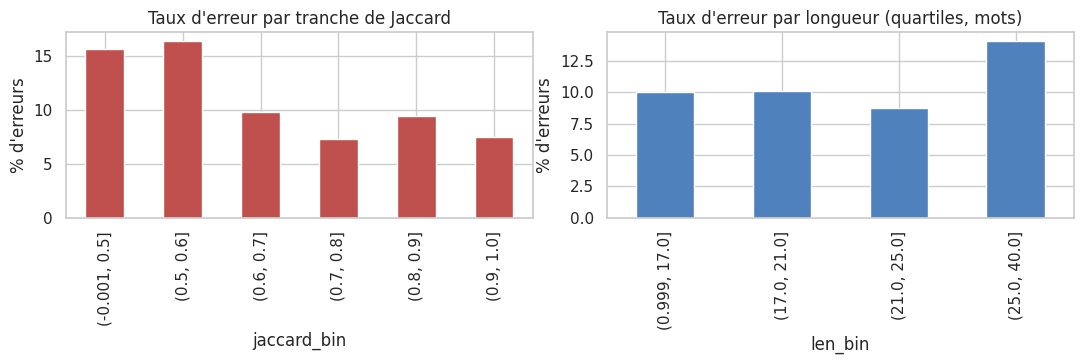

In [ ]:
# Taux d'erreur selon le Jaccard et la longueur
ea["jaccard_bin"] = pd.cut(ea.jaccard, [0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True)
ea["len_bin"] = pd.qcut(ea.n_words_s1, 4, duplicates="drop")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ea.groupby("jaccard_bin").error.mean().mul(100).plot(kind="bar", ax=axes[0], color="#c0504d")
axes[0].set_ylabel("% d'erreurs"); axes[0].set_title("Taux d'erreur par tranche de Jaccard")
ea.groupby("len_bin").error.mean().mul(100).plot(kind="bar", ax=axes[1], color="#4f81bd")
axes[1].set_ylabel("% d'erreurs"); axes[1].set_title("Taux d'erreur par longueur (quartiles, mots)")
save_fig("error_rate_bins")

Le taux d'erreur est le plus élevé pour les paires peu semblables : environ 16 % quand le Jaccard est inférieur à 0,6, contre 7 à 10 % quand il dépasse 0,6. Le modèle se trompe donc plus souvent quand les phrases sont assez différentes (forte reformulation, traduction maladroite) que quand elles sont très proches. Selon la longueur, le taux d'erreur est d'environ 9 à 10 % pour les trois premiers quartiles et monte à environ 14 % pour les phrases les plus longues (plus de 25 mots).

In [ ]:
# Exemples d'erreurs
for t in ["Faux positif", "Faux négatif"]:
    print(f"\n===== {t} : 5 exemples =====")
    display(ea[ea.type == t].sample(min(5, (ea.type == t).sum()), random_state=SEED)[["sentence1", "sentence2", "label", "pred", "tag"]])

# Comparaison avec la meilleure baseline
base_name = "TF-IDF + features + LogReg"
base_ok = PREDS[base_name] == y_test
best_ok = PREDS[best] == y_test
print(f"\nCorrigées par {best} (baseline fausse, modèle juste) : {(~base_ok & best_ok).sum()}")
print(f"Introduites par {best} (baseline juste, modèle faux)  : {(base_ok & ~best_ok).sum()}")

# Export de 50 erreurs à annoter manuellement
to_annotate = ea[ea.error].sample(min(50, ea.error.sum()), random_state=SEED)[["sentence1", "sentence2", "label", "pred", "type", "tag"]].copy()
to_annotate["categorie_manuelle"] = ""
to_annotate.to_csv(f"{RES_DIR}/erreurs_a_annoter.csv", index=False)
print(f"\n{len(to_annotate)} erreurs exportées dans {RES_DIR}/erreurs_a_annoter.csv -> remplir la colonne 'categorie_manuelle'")


===== Faux positif : 5 exemples =====


,sentence1,sentence2,label,pred,tag
910,"Un A Khap est un clan ou un groupe de clans apparentés, principalement sous les Jats de l'ouest de l'Uttar Pradesh et de l'est de l'Haryana.","Un Khap est un clan, ou un groupe de clans apparentés, principalement parmi les Jats de l'est de l'Uttar Pradesh et de l'ouest de l'Haryana.",0,1,noms propres
611,"La rivière Valea lui Lambă ou rivière Șimon est un affluent e la rivière Lom, en Roumanie.","La rivière Valea lui Lambă ou rivière ""unk""' imon est un affluent de la rivière Lom en Roumanie.",0,1,noms propres
269,"Au cours de la mission, 65 soldats furent tués : 34 Nigérians, 28 Tchadiens, 2 Togolais et 1 Burkinabé.","Pendant la mission, 65 soldats ont été tués : 34 tchadiens, 28 nigériens, 2 tongolais et 1 burkinabé.",0,1,noms propres
433,"De plus, un match triple menace pour le championnat des États-Unis opposait les champions Jack Swagger, The Miz et Kofi Kingston.","Il y a avait ensuite un triple match pour le Championnat des États-Unis entre le champion Kofi Kingston, The Mitz et Jack Swagger.",0,1,noms propres
1795,Il s'agissait du troisième des trois hôtels de première classe à être construits dans le quartier central des affaires.,Il était le premier des trois hôtels de troisième catégorie à être construit dans le centre d'affaires.,0,1,autre



===== Faux négatif : 5 exemples =====


,sentence1,sentence2,label,pred,tag
831,"En mai 2011, il écrivit, réalisa et produisit son premier long métrage.","Produit en mai 2011, il réalisa et écrivit son premier long métrage.",1,0,autre
9,Holly a été musicalement influencé par Elton John.,Elton John influença musicalement Holly Holly.,1,0,noms propres
653,"Duminda Silva, également connu sous les noms d'Arumadura Lawrence Romelo Duminda Silva et de R. Dumindha Silva, est un homme politique sri-lankais et un ancien membre du Parlement.","Arumadura Lawrence Romelo Duminda Silva, également connu sous le nom de Duminda Silva et R. Dumindha Silva, est un homme politique du Sri Lanka et un ancien membre du Parlement.",1,0,noms propres
839,Kudawa est un village et la commission pour le développement du village au district de Bara dans la région de Narayani au sud-est du Népal.,"Kudawa est un village et un comité de développement de village situés dans la région de Narayani, dans le district de Bara, au sud-est du Népal.",1,0,autre
528,"Lors de tels dîners, du vin de qualité est souvent consommé, généralement avec du champagne ou des vins mousseux similaires.","Un vin de qualité est généralement consommé lors de tels dîners, souvent avec du champagne ou des vins mousseux similaires en guise de conclusion.",1,0,autre



Corrigées par CamemBERT (fine-tuné) (baseline fausse, modèle juste) : 556
Introduites par CamemBERT (fine-tuné) (baseline juste, modèle faux)  : 102

50 erreurs exportées dans results/erreurs_a_annoter.csv -> remplir la colonne 'categorie_manuelle'


Dans les faux positifs, des noms, des lieux ou des nationalités sont permutés ou modifiés (par exemple Nigérians / Tchadiens) : le modèle juge les phrases proches alors que le sens change. Dans les faux négatifs, ce sont de vraies paraphrases assez reformulées ou avec une traduction maladroite (par exemple « Holly Holly »). Par rapport à la régression logistique, CamemBERT corrige 556 erreurs et en introduit 102.

# PARTIE B — Extension multilingue (XLM-RoBERTa)

Langues : `en`, `fr`, `es`, `de`. On entraîne **XLM-R base** :

- **Monolingue** : un modèle par langue (10 000 exemples), testé sur **les 4 langues**.
  - la diagonale = monolingue (référence) ;
  - la ligne du modèle français hors diagonale = **zero-shot cross-lingue**.
- **Multilingue** : toutes les langues concaténées (4 × 10 000), et une variante à budget égal (10 000 au total).

On obtient une matrice *configuration d'entraînement × langue de test*.

In [ ]:
paws = {l: load_dataset("google-research-datasets/paws-x", l) for l in LANGS}
train_l, val_l, test_l = {}, {}, {}
for i, l in enumerate(LANGS):
    tr = clean_split(paws[l]["train"]).shuffle(seed=SEED + i)      # graine différente par langue -> contenus variés
    train_l[l] = tr.select(range(min(N_PER_LANG, len(tr))))
    val_l[l]   = clean_split(paws[l]["validation"])
    test_l[l]  = clean_split(paws[l]["test"])
    print(f"{l}: train={len(train_l[l])}  val={len(val_l[l])}  test={len(test_l[l])}  %para(test)={np.mean(test_l[l]['label'])*100:.1f}")

EXPERIMENTS = {f"mono-{l}": (train_l[l], val_l[l]) for l in LANGS}
EXPERIMENTS["multi_full"] = (concatenate_datasets([train_l[l] for l in LANGS]).shuffle(seed=SEED),
                             concatenate_datasets([val_l[l] for l in LANGS]).shuffle(seed=SEED))
if RUN_EQUAL_BUDGET:
    per = N_PER_LANG // len(LANGS)
    EXPERIMENTS["multi_equal"] = (concatenate_datasets([train_l[l].select(range(per)) for l in LANGS]).shuffle(seed=SEED),
                                  concatenate_datasets([val_l[l] for l in LANGS]).shuffle(seed=SEED))
for k, (a, b) in EXPERIMENTS.items():
    print(f"{k:<12} train={len(a)}  val={len(b)}")

en/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.43MB            

en/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  310kB            

en/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  307kB            

en/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (38 outputs left out)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

de: train=10000  val=2000  test=2000  %para(test)=44.8
mono-en      train=10000  val=2000
mono-fr      train=10000  val=2000
mono-es      train=10000  val=2000
mono-de      train=10000  val=2000
multi_full   train=40000  val=8000
multi_equal  train=10000  val=8000


Les quatre langues (en, fr, es, de) ont la même taille (10 000 paires d'entraînement par langue, 2 000 en validation et en test) et la même proportion de paraphrases (environ 45 % au test). On compare 6 configurations : un modèle par langue, un modèle multilingue complet (40 000 exemples) et un modèle multilingue à budget égal (10 000 exemples au total).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import inspect
from transformers import TrainingArguments

# Patch de compatibilité pour corriger l'appel à TrainingArguments
_sig = inspect.signature(TrainingArguments.__init__).parameters

_old_finetune = finetune
def finetune_safe(model_name, train_ds, val_ds, out_dir, epochs=EPOCHS_B, batch=BATCH, lr=LR):
    set_seed(SEED)
    tok = AutoTokenizer.from_pretrained(model_name)
    tr, va = tokenize_ds(train_ds, tok), tokenize_ds(val_ds, tok)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    kw = dict(output_dir=out_dir, learning_rate=lr, num_train_epochs=epochs,
              per_device_train_batch_size=batch, per_device_eval_batch_size=64,
              weight_decay=0.01,
              save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1",
              save_total_limit=1, fp16=torch.cuda.is_available(), seed=SEED,
              logging_steps=100, report_to="none")

    if "warmup_ratio" in _sig:
        kw["warmup_ratio"] = 0.1
    else:
        kw["warmup_steps"] = 100

    kw[EVAL_KEY] = "epoch"
    trainer_kw = dict(model=model, args=TrainingArguments(**kw), train_dataset=tr, eval_dataset=va,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=hf_metrics)
    trainer_kw[TOK_KEY] = tok
    trainer = Trainer(**trainer_kw)
    t0 = time.time()
    trainer.train()
    return trainer, tok, time.time() - t0

CROSS = {}   # configuration -> {langue_test: métriques}

def run_experiment(tag, train_ds, val_ds):
    cache = f"{RES_DIR}/partB_{tag}.json"
    if os.path.exists(cache):
        print(f"[{tag}] résultats déjà présents, on saute l'entraînement")
        return json.load(open(cache))
    print(f"\n================ {tag} ================")
    ckpt = f"{MODEL_DIR}/ckpt_B_{tag}"
    trainer, tok, secs = finetune_safe("xlm-roberta-base", train_ds, val_ds, ckpt, epochs=EPOCHS_B)
    row = {}
    for l in LANGS:
        probs, y = predict_split(trainer, tok, test_l[l])
        row[l] = compute_all(y, probs.argmax(1))
        print(f"  test {l}: acc={row[l]['accuracy']:.4f}  f1={row[l]['f1']:.4f}")
    row["_train_min"] = secs / 60
    if tag == "multi_full":
        trainer.save_model(f"{MODEL_DIR}/xlmr_multi"); tok.save_pretrained(f"{MODEL_DIR}/xlmr_multi")
    json.dump(row, open(cache, "w"))
    del trainer, tok
    shutil.rmtree(ckpt, ignore_errors=True)
    free_gpu()
    return row

for tag, (tr_ds, va_ds) in EXPERIMENTS.items():
    CROSS[tag] = run_experiment(tag, tr_ds, va_ds)


================ mono-en ================


Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.689038,0.679628,0.567000,0.463415,0.022016,0.042035
2,0.355762,0.340265,0.877500,0.826638,0.906141,0.864566
3,0.264391,0.292820,0.892500,0.857616,0.900348,0.878462


... (67 outputs left out)

  test en: acc=0.8975  f1=0.8867


  test fr: acc=0.8540  f1=0.8331


  test es: acc=0.8575  f1=0.8396


  test de: acc=0.8290  f1=0.7969


Chaque configuration est entraînée avec XLM-R puis testée sur les 4 langues. Les résultats sont enregistrés en JSON pour éviter de réentraîner si la cellule est relancée. L'analyse est faite dans la cellule suivante.

Accuracy (lignes = configuration d'entraînement, colonnes = langue de test)


,en,fr,es,de,moyenne
mono-en,91.0,85.9,85.9,84.9,86.9
mono-fr,87.0,84.9,84.5,81.6,84.5
mono-es,85.4,85.0,85.8,82.6,84.7
mono-de,89.6,86.1,84.7,84.4,86.2
multi_full,94.3,90.0,89.6,87.7,90.4
multi_equal,89.8,85.4,85.8,82.9,85.9


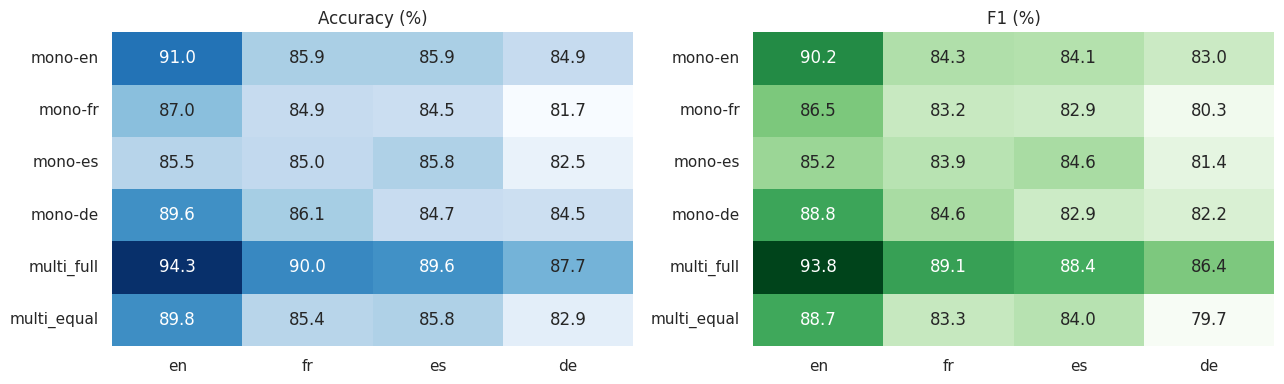


Zero-shot depuis le français (accuracy) :
  fr -> en : 87.0 %  (monolingue en->en : 91.0 %, écart = +4.0 pts)
  fr -> es : 84.5 %  (monolingue es->es : 85.8 %, écart = +1.3 pts)
  fr -> de : 81.7 %  (monolingue de->de : 84.5 %, écart = +2.8 pts)


In [ ]:
acc = pd.DataFrame({t: {l: r[l]["accuracy"] for l in LANGS} for t, r in CROSS.items()}).T[LANGS]
f1  = pd.DataFrame({t: {l: r[l]["f1"] for l in LANGS} for t, r in CROSS.items()}).T[LANGS]
acc["moyenne"] = acc.mean(axis=1)
acc.to_csv(f"{RES_DIR}/partB_accuracy_matrix.csv"); f1.to_csv(f"{RES_DIR}/partB_f1_matrix.csv")
print("Accuracy (lignes = configuration d'entraînement, colonnes = langue de test)")
display((acc * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(acc[LANGS] * 100, annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar=False); axes[0].set_title("Accuracy (%)")
sns.heatmap(f1 * 100, annot=True, fmt=".1f", cmap="Greens", ax=axes[1], cbar=False); axes[1].set_title("F1 (%)")
save_fig("partB_cross_lingual_matrix")

# Perte de transfert zero-shot (modèle entraîné sur le français)
if "mono-fr" in acc.index:
    print("\nZero-shot depuis le français (accuracy) :")
    for l in LANGS:
        if l != "fr":
            print(f"  fr -> {l} : {acc.loc['mono-fr', l]*100:.1f} %  (monolingue {l}->{l} : {acc.loc[f'mono-{l}', l]*100:.1f} %, écart = {(acc.loc[f'mono-{l}', l]-acc.loc['mono-fr', l])*100:+.1f} pts)")

Lecture des matrices (lignes = données d'entraînement, colonnes = langue de test) :
- **Monolingue (diagonale)** : 91,0 % en anglais, 84,9 % en français, 85,8 % en espagnol, 84,5 % en allemand. L'anglais est la langue la plus facile et l'allemand la plus difficile, pour presque toutes les lignes.
- **Zero-shot depuis le français** : 87,0 % en anglais, 84,5 % en espagnol et 81,7 % en allemand. La perte par rapport au modèle entraîné dans la langue est de 1,3 à 4 points : le transfert fonctionne bien. Le modèle entraîné sur l'allemand transfère un peu mieux (moyenne de 86,2 %) que ceux entraînés sur le français (84,5 %) ou l'espagnol (84,7 %). Certains écarts d'environ 1 point (par exemple `mono-de` à 86,1 % contre `mono-fr` à 84,9 % sur le test français) sont du même ordre que l'incertitude : un seul entraînement par configuration et 2 000 paires de test.
- **Multilingue à budget égal** (`multi_equal`) : 85,9 % de moyenne, proche des modèles monolingues (84,5 à 86,9 %). Il n'y a pas de gain net.
- **Multilingue complet** (`multi_full`) : 90,4 % de moyenne, meilleur dans les quatre langues (+3,5 points par rapport au meilleur modèle monolingue), mais avec 4 fois plus de données.
- **F1** : il suit les mêmes tendances que l'accuracy, avec des valeurs un peu plus basses (environ 1 à 3 points). Le cas le plus faible est `multi_equal` testé sur l'allemand (79,7 %).
- **Comparaison avec la partie A** : XLM-R fine-tuné sur 20 000 paires françaises atteint 88,75 % en français, contre 84,9 % avec 10 000 paires (`mono-fr`). Avec `multi_full`, qui contient seulement 10 000 paires françaises et 30 000 paires dans les autres langues, il atteint 90,0 % en français. Cela suggère que les autres langues apportent de l'information utile.

**Conclusion de la partie B :** le modèle entraîné dans une seule langue reste bon dans les autres langues (zero-shot : 1,3 à 4 points de moins). À nombre d'exemples égal, l'entraînement multilingue n'apporte pas de gain clair (`multi_equal`, 85,9 % de moyenne). Avec 4 fois plus de données (`multi_full`), le gain est net (90,4 %). Le multilingue est donc surtout utile parce qu'il permet de rassembler plus de données, tout en gardant un seul modèle pour les quatre langues.

## B.bonus — Vraies paires cross-lingues (phrase 1 dans une langue, phrase 2 dans une autre)

Les exemples de PAWS-X sont alignés entre langues (même `id`). On vérifie l'alignement, puis on fabrique des paires mixtes
et on les évalue avec le modèle multilingue `xlmr_multi`.

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

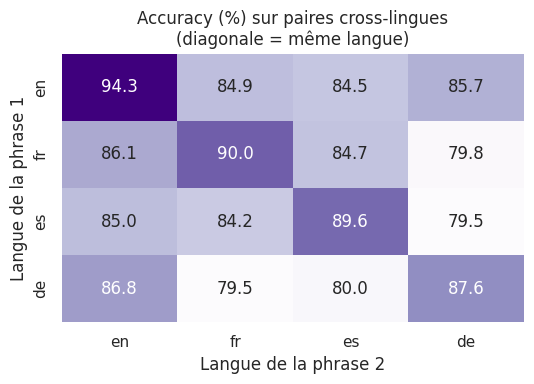

In [ ]:
 @torch.no_grad()
def predict_pairs(model, tok, s1, s2, batch_size=64):
    model.eval()
    dev = next(model.parameters()).device
    out = []
    for i in range(0, len(s1), batch_size):
        enc = tok(list(s1[i:i+batch_size]), list(s2[i:i+batch_size]), truncation=True, max_length=MAX_LEN,
                  padding=True, return_tensors="pt").to(dev)
        out.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
    return np.concatenate(out)

multi_tok = AutoTokenizer.from_pretrained(f"{MODEL_DIR}/xlmr_multi")
multi_model = AutoModelForSequenceClassification.from_pretrained(f"{MODEL_DIR}/xlmr_multi").to(DEVICE)

test_raw = {l: paws[l]["test"].to_pandas() for l in LANGS}
mixed = pd.DataFrame(index=LANGS, columns=LANGS, dtype=float)
for la in LANGS:
    for lb in LANGS:
        m = test_raw[la].merge(test_raw[lb], on="id", suffixes=("_a", "_b"))
        agree = (m.label_a == m.label_b).mean()
        if agree < 0.99:
            print(f"Attention : alignement douteux {la}/{lb} (labels concordants : {agree*100:.1f} %)")
        m = m[(m.label_a == m.label_b) & m.sentence1_a.notna() & m.sentence2_b.notna()]
        probs = predict_pairs(multi_model, multi_tok, m.sentence1_a.tolist(), m.sentence2_b.tolist())
        mixed.loc[la, lb] = accuracy_score(m.label_a.values, probs.argmax(1))

plt.figure(figsize=(5.5, 4))
sns.heatmap(mixed * 100, annot=True, fmt=".1f", cmap="Purples", cbar=False)
plt.xlabel("Langue de la phrase 2"); plt.ylabel("Langue de la phrase 1")
plt.title("Accuracy (%) sur paires cross-lingues\n(diagonale = même langue)")
save_fig("partB_mixed_language_pairs")
mixed.to_csv(f"{RES_DIR}/partB_mixed_pairs_accuracy.csv")

La diagonale (même langue) reprend les résultats de `multi_full` : 94,3 % en anglais, 90,0 % en français, 89,6 % en espagnol et 87,6 % en allemand. Pour les paires dont les deux phrases sont dans des langues différentes, l'accuracy est de 79,5 à 86,8 %, soit 3 à 10 points de moins. Les paires qui contiennent de l'anglais sont les mieux traitées (84,5 à 86,8 %). Les paires allemand-français et allemand-espagnol sont les plus difficiles (environ 80 %). Les paires français-espagnol sont intermédiaires (environ 84 à 85 %). Le modèle sait donc comparer des phrases de langues différentes, mais moins bien que des phrases de la même langue.

# Test d'inférence (avant l'app Streamlit)

Vérifie que les modèles sauvegardés se rechargent et prédisent correctement : c'est exactement ce que fera `app.py`.

In [ ]:
def load_model(path):
    return AutoTokenizer.from_pretrained(path), AutoModelForSequenceClassification.from_pretrained(path).to(DEVICE)

examples = [
    ("Il a quitté l'entreprise en 2010 pour fonder sa propre société.", "En 2010, il a quitté l'entreprise afin de créer sa propre société."),
    ("Marie a présenté Paul à Jean.", "Paul a présenté Marie à Jean."),
    ("The dog chased the cat across the garden.", "The cat chased the dog across the garden."),
    ("La ville est située au nord de la rivière.", "La ville se trouve au nord de la rivière."),
]
for path in [f"{MODEL_DIR}/xlmr_fr", f"{MODEL_DIR}/camembert_fr", f"{MODEL_DIR}/xlmr_multi"]:
    if not os.path.isdir(path):
        continue
    tok_i, model_i = load_model(path)
    probs = predict_pairs(model_i, tok_i, [a for a, _ in examples], [b for _, b in examples])
    print(f"\n=== {path} ===")
    for (a, b), p in zip(examples, probs):
        print(f"  {'PARAPHRASE' if p[1] > 0.5 else 'NON-PARAPHRASE':<15} (P(para)={p[1]:.2f}) | {a}  <->  {b}")
    del tok_i, model_i
    free_gpu()

## Récapitulatif des fichiers produits

| Dossier | Contenu | Utilisation |
|---|---|---|
| `figures/` | Toutes les figures (EDA, courbes d'entraînement, matrices de confusion, matrice cross-lingue...) | Rapport + PPT |
| `results/` | `partA_resultats.csv`, `partB_*.csv`, `erreurs_a_annoter.csv`... | Tableaux du rapport, annotation manuelle |
| `models/xlmr_fr`, `models/camembert_fr` | Modèles français fine-tunés | App Streamlit (choix du modèle) |
| `models/xlmr_multi` | Modèle multilingue | App Streamlit (démo multilingue) |

**Prochaine étape :** application Streamlit (`app.py`) qui charge ces modèles avec `@st.cache_resource`.

## Résumé et conclusion

**Objectif.** Détecter si deux phrases sont des paraphrases avec PAWS-X, d'abord en français (partie A), puis en multilingue (partie B).

**Partie A – français (test de 2 000 paires)**
- Les deux phrases d'une paire ont presque les mêmes mots dans les deux classes. Le recouvrement lexical ne suffit donc pas, et l'ordre des mots compte.
- Les baselines restent faibles : 66 à 68 % d'accuracy pour TF-IDF avec variables de similarité, 46 à 59 % pour les embeddings MiniLM, contre 54,85 % pour le classifieur majoritaire.
- Les cross-encoders fine-tunés sont bien meilleurs : **CamemBERT 89,3 % (F1 0,885)** et **XLM-R 88,75 % (F1 0,877)**. CamemBERT est le meilleur et s'entraîne plus vite.
- L'analyse d'erreurs (10,7 % d'erreurs pour CamemBERT) montre surtout des faux positifs, avec des noms, des lieux ou des nombres modifiés. Les erreurs sont plus fréquentes pour les paires peu semblables (Jaccard inférieur à 0,6) et pour les phrases longues.

**Partie B – multilingue (XLM-R)**
- Le transfert zero-shot du français vers les autres langues perd entre 1,3 et 4 points : le modèle généralise bien d'une langue à l'autre.
- À nombre d'exemples égal, entraîner sur plusieurs langues n'apporte pas de gain net. Avec 4 fois plus de données (`multi_full`), tous les résultats progressent (90,4 % de moyenne).
- Sur des paires dont les deux phrases sont dans des langues différentes, l'accuracy est de 79,5 à 86,8 %, plus faible que sur des paires de la même langue.

**Limites.** Chaque modèle est entraîné une seule fois (une seule graine) et le test contient 2 000 paires : les écarts d'environ 1 point ne sont pas fiables. Le train est traduit automatiquement, ce qui ajoute du bruit. Les catégories d'erreurs sont des étiquettes automatiques.